# Strip waveguide bend
This notebook contains code that simulates bend waveguide parameters using **Lumerical MODE**. \
The objective is to obtain loss values across radius sweep.

https://www.flexcompute.com/tidy3d/examples/notebooks/RadiativeLossesModeSolver/

In [23]:
%%capture

# Install dependencies specified in pyproject.toml
!uv pip install --reinstall --refresh -r pyproject.toml

# Import modules
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import photonix as px
import tidy3d as td
from tidy3d.plugins.dispersion import FastDispersionFitter
from tidy3d.plugins.mode import ModeSolver

print(f"Tidy3d version: {td.__version__}")

In [24]:
%%html

<!-- Align table to the left -->
<style>
  table {margin-left: 0 !important;}
</style>

In [25]:
# Constants

um = 1e-6
nm = 1e-9

# Simulation input

| Parameter                 | Description                                                                                   | Example                |
| :------------------------ | :-------------------------------------------------------------------------------------------- | :--------------------- |
| **wavelength_center**     | Wavelength for which simulation will be done. (i)                                             | `1.55*um`              |
| **core_thickness**        | Thickness of the burried oxide strip waveguide core.                                          | `220*nm`               |
| **core_width**            | Width of the strip waveguide core.                                                            | `500*nm`               |
| **core material**         | Material of strip waveguide core as defined in materials library of specified solver backend. | `Si (Silicon) - Palik` |
| **clad material**         | Material of strip waveguide clad as defined in materials library of specified solver backend. | `SiO2 (Glass) - Palik` |
| **top_clad_thickness**    | Thickness of the top clad layer.                                                              | `5*µm`                 |
| **bottom_clad_thickness** | Thickness of the bottom clad layer.                                                           | `5*µm`                 |

`top_clad_thickness` and `bottom_clad_thickness` are used to pre-calculate FDE window size. \
They are not that relevant from the simulation perspective but setting too large values will result in longer computation time during intial FDE size optimization.

In [26]:
# Si/SiO2 500x220nm 1550nm

radius_sweep = np.arange(1*um, 20*um, 0.5*um)

wavelength_center = 1.55*um
core_thickness = 220*nm
core_width = 500*nm

bottom_clad_thickness = 3*um
top_clad_thickness = 2*um

# https://docs.flexcompute.com/projects/tidy3d/en/stable/api/material_library.html
core_material = "cSi Palik_LowLoss"
clad_material = "SiO2 Palik_LowLoss"
substrate_material = "cSi Palik_LowLoss"

In [27]:
# Si3N4/SiO2 1000x360nm 1550nm

radius_sweep = np.arange(20*um, 35*um, 0.5*um)

wavelength_center = 1.55*um
core_thickness = 360*nm
core_width = 1000*nm

bottom_clad_thickness = 5*um
top_clad_thickness = 5*um

# https://docs.flexcompute.com/projects/tidy3d/en/stable/api/material_library.html
core_material = "Si3N4 Luke2015PMLStable"
clad_material = "SiO2 Palik_LowLoss"
substrate_material = "cSi Palik_LowLoss"

In [28]:
field_intensity_log_decay = -6
initial_fde_width = core_width * 3

In [29]:
frequency_center = (td.C_0*1e-6)/ wavelength_center

In [30]:
# Materials

# Helper to fit materials
def fit_material(mat):
    wavelength_min = wavelength_center - 150*nm
    wavelength_max = wavelength_center + 150*nm
    wavelengths = np.linspace(wavelength_min, wavelength_max, 50)
    freqs = (td.C_0 * 1e-6)/wavelengths

    eps = np.array([mat.eps_model(f) for f in freqs])
    n, k = np.real(np.sqrt(eps)), np.imag(np.sqrt(eps))
    fitter = FastDispersionFitter(
      wvl_um=wavelengths*1e6, n_data=n, k_data=k, wvl_range=(wavelength_min*1e6, wavelength_min*1e6)
    )
    fitted, _ = fitter.fit(min_num_poles=1, max_num_poles=6, tolerance_rms=0.001)
    return fitted

# Core
core_material_name, core_material_model = core_material.split()
core_material = td.material_library[core_material_name][core_material_model]
core_material = fit_material(core_material)

# Clad
clad_material_name, clad_material_model = clad_material.split()
clad_material = td.material_library[clad_material_name][clad_material_model]
clad_material = fit_material(clad_material)

# Substrate
substrate_material_name, substrate_material_model = substrate_material.split()
substrate_material = td.material_library[substrate_material_name][substrate_material_model]
substrate_material = fit_material(substrate_material)

Output()

Output()

Output()

In [31]:
# Structure geometry

# tidy3d is operating with um
core_thickness_um = core_thickness*1e6
core_width_um = core_width*1e6
bottom_clad_thickness_um = bottom_clad_thickness*1e6
top_clad_thickness_um = top_clad_thickness*1e6

# Core
core = td.Structure(
    name="core",
    geometry=td.Box(
        center=(0, 0, 0),
        size=(core_width_um, td.inf, core_thickness_um)
    ),
    medium=core_material
)

# Clad
clad_thickness_um = bottom_clad_thickness_um + core_thickness_um + top_clad_thickness_um
clad = td.Structure(
    name="clad",
    geometry=td.Box(
        center=(0, 0, 0),
        size=(td.inf, td.inf, clad_thickness_um)
    ),
    medium=clad_material
)

# Substrate
clad_z_min_um = clad.geometry.bounds[0][2]
substrate_thickness_um = 100
substrate = td.Structure(
    name="substrate",
    geometry=td.Box.from_bounds(
        rmax=(td.inf, td.inf, clad_z_min_um),
        rmin=(-td.inf, -td.inf, clad_z_min_um - substrate_thickness_um),
    ),
    medium=substrate_material
)

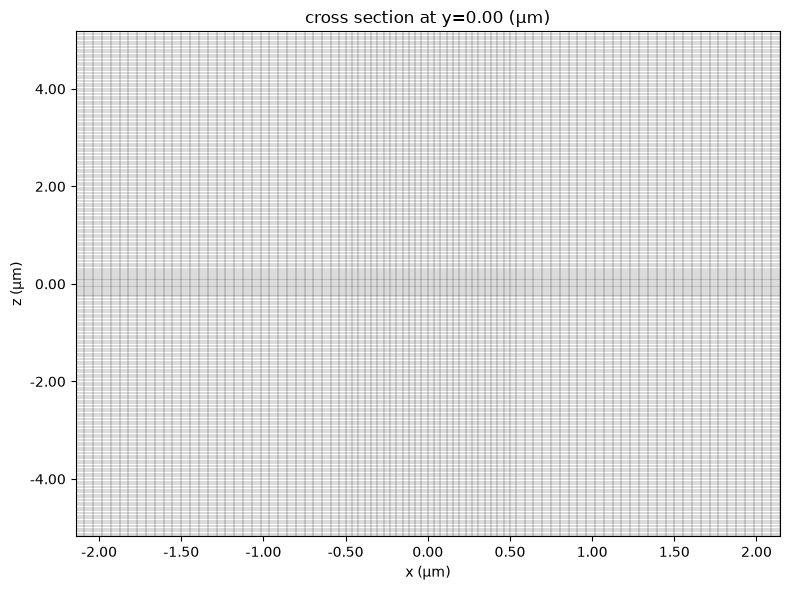

In [11]:
# Simulation setup

# Grid
min_steps_per_wvl=20

# For substrate apply 2x coarser mesh than in clad
clad_n, _ = clad_material.nk_model(frequency_center)
sdl_um = 2*px.calc_grid_dl(wavelength_center, clad_n, min_steps_per_wvl)*1e6

substrate_mesh_override = td.MeshOverrideStructure(
    geometry=substrate.geometry,
    dl=(sdl_um, sdl_um, sdl_um)
)

grid = td.GridSpec.auto(
    wavelength=1.55,
    min_steps_per_wvl=min_steps_per_wvl,
    override_structures=[substrate_mesh_override]
)

# Boundries
boundries = td.BoundarySpec(
    x=td.Boundary.pml(),
    y=td.Boundary.pml(),
    z=td.Boundary(
        minus=td.PECBoundary(), 
        plus=td.PECBoundary()
    ),
)

# XZ plane
plane = td.Box(
    center=(0, 0, 0), 
    size=(td.inf, 0, td.inf)
)

initial_fde_width_um = initial_fde_width*1e6
initial_fde_hight_um = clad_thickness_um
sim = td.Simulation(
    size=(initial_fde_width_um, 0.1, initial_fde_hight_um),
    boundary_spec=boundries,
    grid_spec=grid,
    structures=[substrate, clad, core],
    run_time=3e-13,
)

# Mode solver
sort_spec=td.ModeSortSpec(
    sort_key="fill_fraction_box",
    bounding_box=core.geometry,
)

mode_spec=td.ModeSpec(
    num_modes=4,
    precision="double",
    num_pml=(12, 12),
    sort_spec=sort_spec,
)

mode_solver = ModeSolver(
    freqs=[frequency_center],
    plane=plane,
    simulation=sim,
    mode_spec=mode_spec,
)

# Preview
sim.plot_3d()
fig, ax = plt.subplots(figsize=(8, 6), tight_layout=True)
# sim.plot(y=0, ax=ax)
sim.plot_grid(y=0, ax=ax)
plt.show()

wavelength     n eff         k eff  loss (dB/cm)  \
f            mode_index                                                     
1.934145e+14 0                 1.55  1.641709 -3.169529e-08     -0.011160   
             1                 1.55  1.551749 -3.986924e-06     -1.403785   
             2                 1.55  1.442182  1.129295e-03    397.621347   
             3                 1.55  1.442518  2.618927e-03    922.116667   

                         TE (Ex) fraction  wg TE fraction  wg TM fraction  \
f            mode_index                                                     
1.934145e+14 0                   0.995874        0.916175        0.890408   
             1                   0.007932        0.874442        0.948596   
             2                   0.957103        0.962380        0.986222   
             3                   0.999946        0.996655        0.994591   

                         mode area  
f            mode_index             
1.934145e+14 0            0.811412  
             1            1.326951  
             2           12.468944  
             3           36.804207

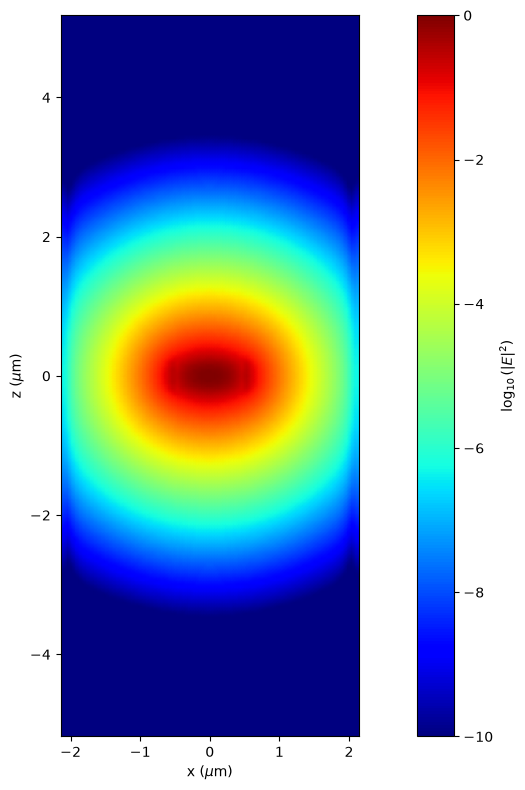

Field decay: -3.9260495270134768
Relative confinement: 0.990753709306663


In [12]:
# Initial simulation
mode_data = mode_solver.solve()
mode_df = mode_data.to_dataframe()
display(mode_df)

Ex, Ey, Ez = (getattr(mode_data, c).isel(mode_index=0, f=0) for c in ["Ex", "Ey", "Ez"])
x, z = mode_data.Ex.x, mode_data.Ex.z

fig = px.plot_field(
    Ex, Ey, Ez, 
    x=x, z=z,
    vmin=-10, vmax=0,
)
plt.show()

decay = px.get_field_decay(Ex, Ey, Ez, margin=12)
confinement = px.get_field_confinement(Ex, Ey, Ez, x=x, z=z, radius=core_width_um)

print(f"Field decay: {decay}")
print(f"Relative confinement: {confinement}")
last_neff = mode_data.n_eff.sel(mode_index=0).item()

In [13]:
# Calculate FDE width

def update_solver_width(mode_solver, fde_width_um):
    print(f"New fde width: {fde_width_um}")
    mode_solver = mode_solver.updated_copy(
        simulation = sim.updated_copy(
            size=(fde_width_um, sim.size[1], sim.size[2])
        )
    )

    return mode_solver

def ensure_solver_decay(mode_data, mode_solver, target_decay):
    Ex, Ey, Ez = (getattr(mode_data, c).isel(mode_index=0, f=0) for c in ["Ex", "Ey", "Ez"])
    x, z = mode_data.Ex.x, mode_data.Ex.z

    old_fde_width_um = mode_solver.simulation.size[0]
    
    # Right X side
    slope_xp, intercept_xp = px.get_decay_slope(
        Ex, Ey, Ez, 
        x=x, 
        amin=core_width_um/2,
        amax=old_fde_width_um/2,
    )
    # Left X side
    slope_xm, intercept_xm = px.get_decay_slope(
        Ex, Ey, Ez,
        x=x,
        amin=-old_fde_width_um/2,
        amax=-core_width_um/2,
    )

    slope = min(abs(slope_xp), abs(slope_xm))
    intercept = min(intercept_xp, intercept_xm)

    x_target = (target_decay - intercept) / slope
    predicted_fde_width_um = abs(x_target) * 2

    new_fde_width_um = max(old_fde_width_um, predicted_fde_width_um)*1.1
    return update_solver_width(mode_solver, new_fde_width_um)

# Update width
mode_solver = ensure_solver_decay(mode_data, mode_solver, field_intensity_log_decay)

New fde width: 4.741561301341958


wavelength     n eff         k eff  loss (dB/cm)  \
f            mode_index                                                     
1.934145e+14 0                 1.55  1.643851  3.266045e-09      0.001150   
             1                 1.55  1.554720 -5.871086e-08     -0.020672   
             2                 1.55  1.443030  8.633230e-04    303.973543   
             3                 1.55  1.443085  1.850970e-03    651.721373   

                         TE (Ex) fraction  wg TE fraction  wg TM fraction  \
f            mode_index                                                     
1.934145e+14 0                   0.996610        0.918110        0.890548   
             1                   0.007617        0.872503        0.950149   
             2                   0.960189        0.975497        0.990636   
             3                   0.999998        0.997598        0.995989   

                         mode area  
f            mode_index             
1.934145e+14 0            0.804508  
             1            1.338782  
             2           23.430148  
             3           48.426374

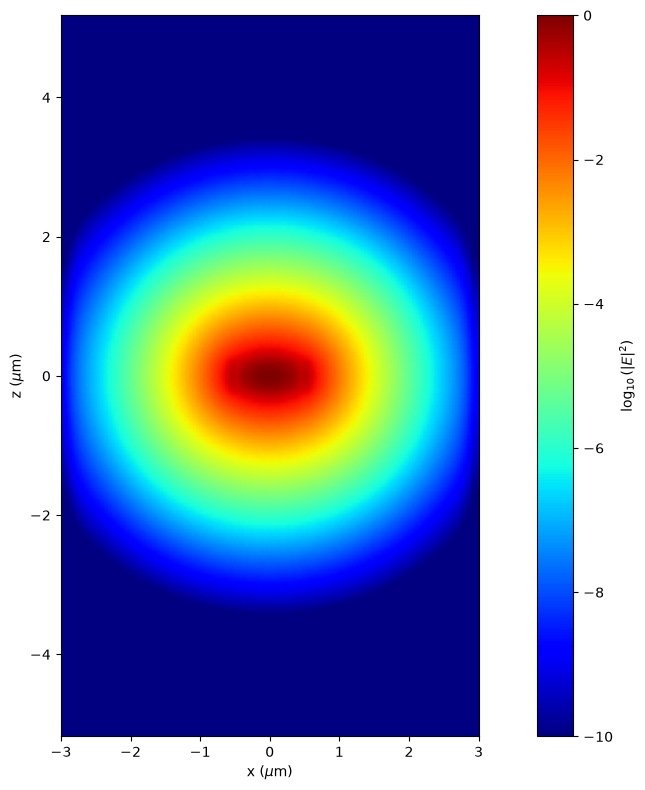

Field decay: -6.564758480492971
Relative confinement: 0.9910125052398674


In [14]:
# Rerun simulation with new FDE width

mode_data = mode_solver.solve()
mode_df = mode_data.to_dataframe()
display(mode_df)

Ex, Ey, Ez = (getattr(mode_data, c).isel(mode_index=0, f=0) for c in ["Ex", "Ey", "Ez"])
x, z = mode_data.Ex.x, mode_data.Ex.z

fig = px.plot_field(
    Ex, Ey, Ez, 
    x=x, z=z,
    vmin=-10, vmax=0,
)
plt.show()

decay = px.get_field_decay(Ex, Ey, Ez, margin=12)
confinement = px.get_field_confinement(Ex, Ey, Ez, x=x, z=z, radius=core_width_um)

print(f"Field decay: {decay}")
print(f"Relative confinement: {confinement}")
last_neff = mode_data.n_eff.sel(mode_index=0).item()

---------------- Calculating for radius: 34.5 µm ----------------
Solver radius: 34.5, Target neff: 1.643851
Field decay: -5.516157873156015
---------------- Optimizing decay: -5.52 ----------------
New fde width: 5.54475738553167
Field decay: -6.245868586491479


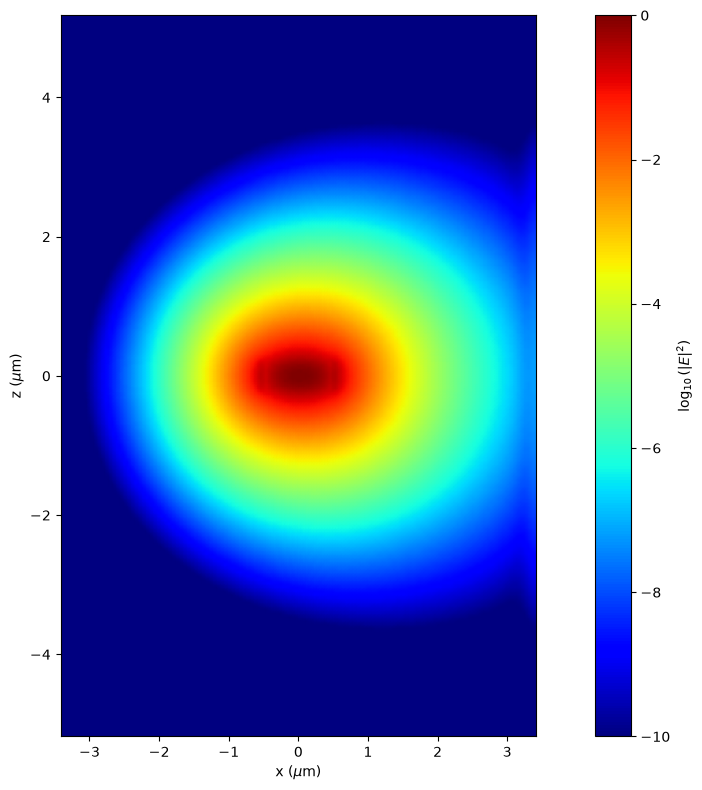

wavelength          1.550000e+00
n eff               1.642100e+00
k eff               3.766505e-09
loss (dB/cm)        1.326176e-03
TE (Ex) fraction    9.959184e-01
wg TE fraction      9.166419e-01
wg TM fraction      8.906963e-01
mode area           8.142536e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 34.0 µm ----------------
Solver radius: 34.0, Target neff: 1.642100
Field decay: -6.222256334932188


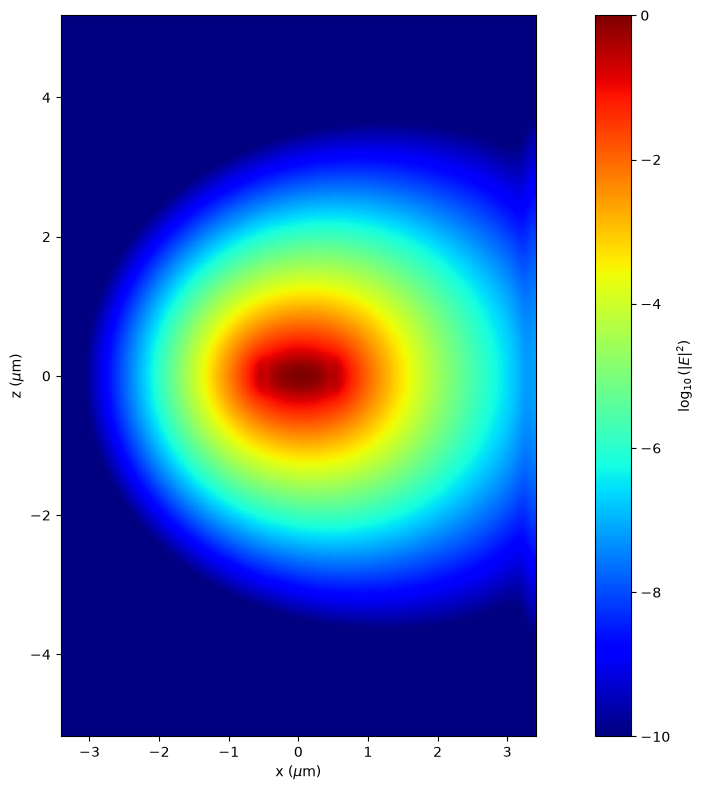

wavelength          1.550000e+00
n eff               1.642117e+00
k eff               3.356266e-09
loss (dB/cm)        1.181731e-03
TE (Ex) fraction    9.959174e-01
wg TE fraction      9.166573e-01
wg TM fraction      8.907040e-01
mode area           8.143645e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 33.5 µm ----------------
Solver radius: 33.5, Target neff: 1.642117
Field decay: -6.197756732246822


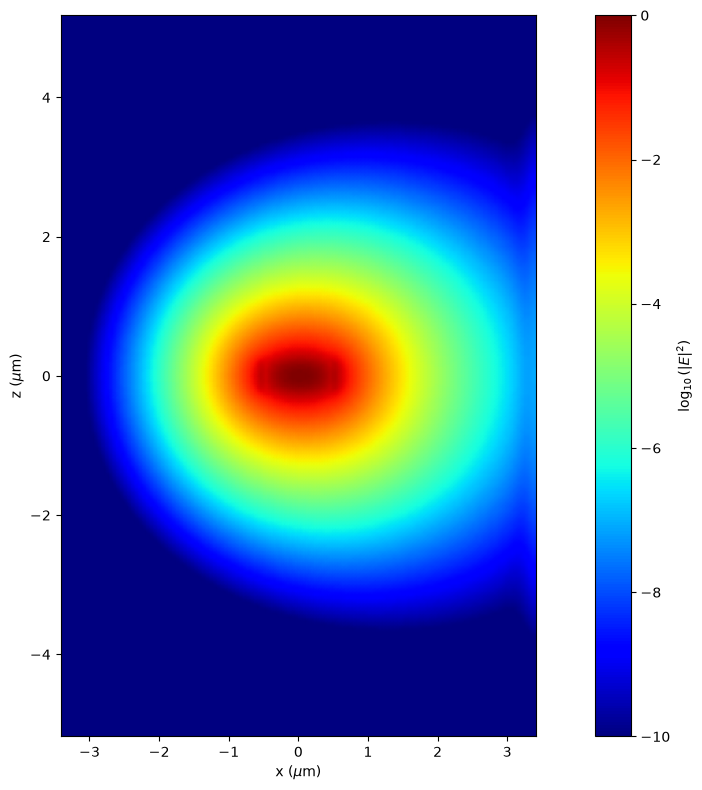

wavelength          1.550000e+00
n eff               1.642135e+00
k eff               2.824096e-09
loss (dB/cm)        9.943560e-04
TE (Ex) fraction    9.959163e-01
wg TE fraction      9.166734e-01
wg TM fraction      8.907120e-01
mode area           8.144812e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 33.0 µm ----------------
Solver radius: 33.0, Target neff: 1.642135
Field decay: -6.172297873950432


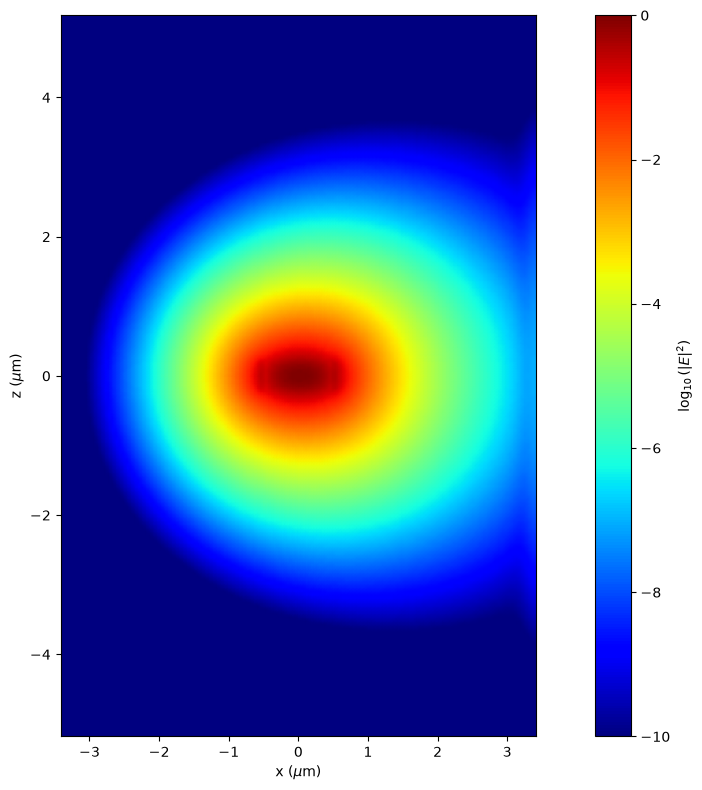

wavelength          1.550000e+00
n eff               1.642153e+00
k eff               2.137635e-09
loss (dB/cm)        7.526551e-04
TE (Ex) fraction    9.959151e-01
wg TE fraction      9.166903e-01
wg TM fraction      8.907204e-01
mode area           8.146040e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 32.5 µm ----------------
Solver radius: 32.5, Target neff: 1.642153
Field decay: -6.145795637568881


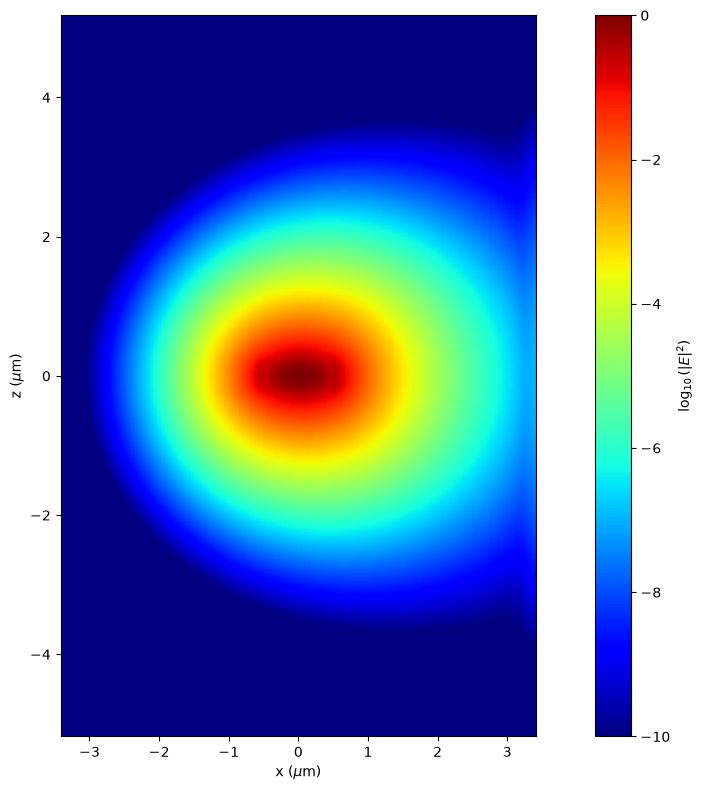

wavelength          1.550000e+00
n eff               1.642173e+00
k eff               1.255594e-09
loss (dB/cm)        4.420912e-04
TE (Ex) fraction    9.959139e-01
wg TE fraction      9.167081e-01
wg TM fraction      8.907292e-01
mode area           8.147333e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 32.0 µm ----------------
Solver radius: 32.0, Target neff: 1.642173
Field decay: -6.1181504097464625


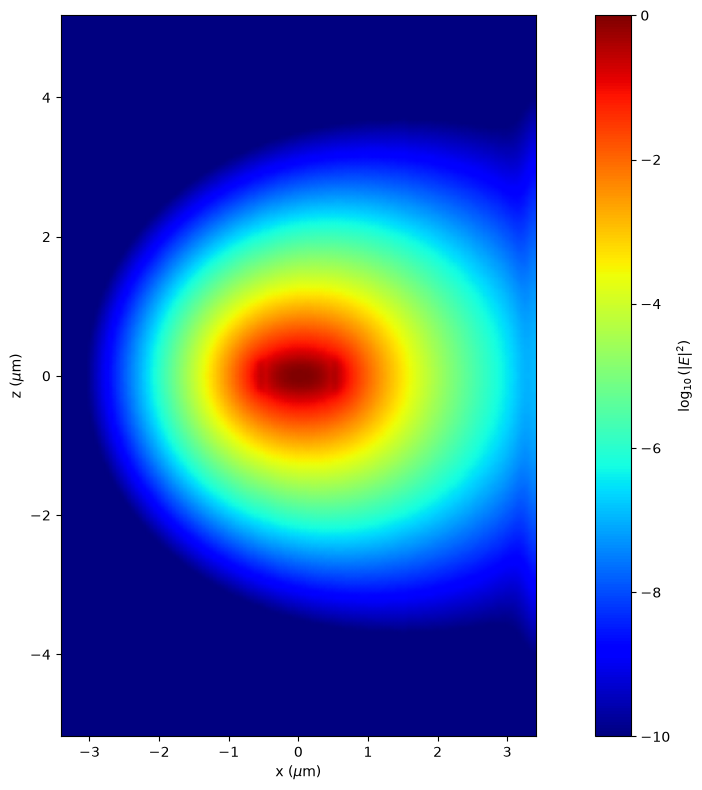

wavelength          1.550000e+00
n eff               1.642193e+00
k eff               1.251544e-10
loss (dB/cm)        4.406652e-05
TE (Ex) fraction    9.959125e-01
wg TE fraction      9.167268e-01
wg TM fraction      8.907384e-01
mode area           8.148697e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 31.5 µm ----------------
Solver radius: 31.5, Target neff: 1.642193
Field decay: -6.089242720377263


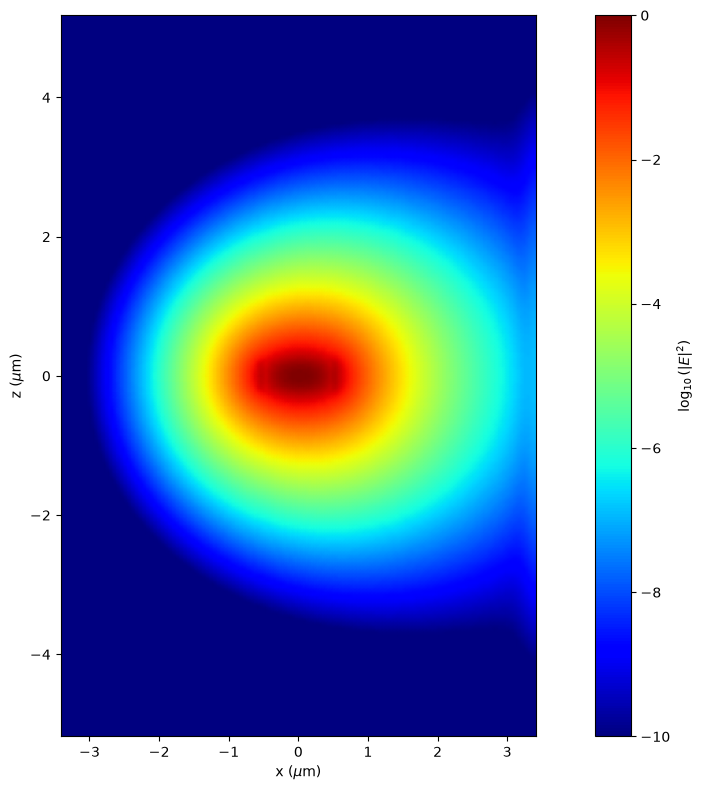

wavelength          1.550000e+00
n eff               1.642215e+00
k eff              -1.321415e-09
loss (dB/cm)       -4.652664e-04
TE (Ex) fraction    9.959110e-01
wg TE fraction      9.167464e-01
wg TM fraction      8.907481e-01
mode area           8.150136e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 31.0 µm ----------------
Solver radius: 31.0, Target neff: 1.642215
Field decay: -6.058927376744869


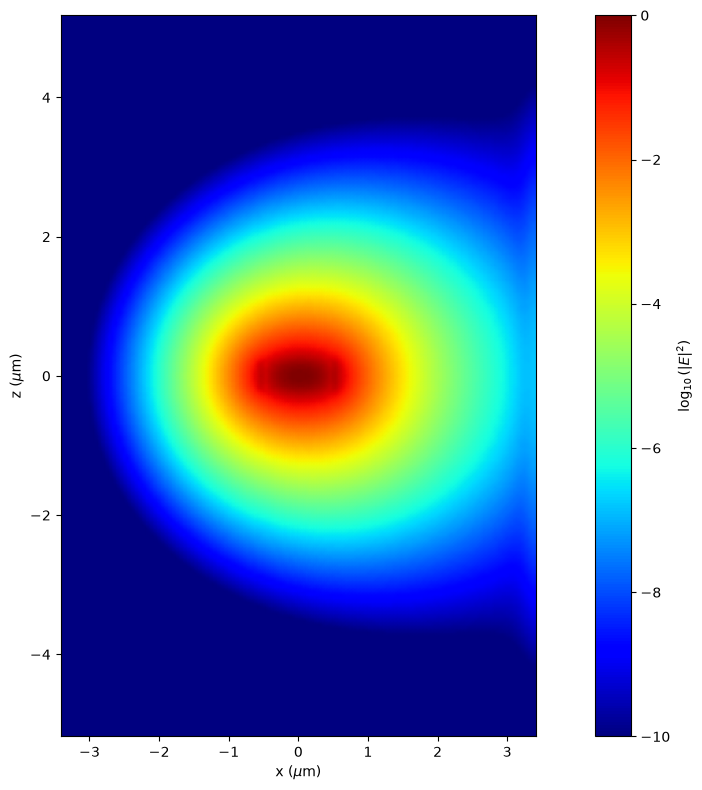

wavelength          1.550000e+00
n eff               1.642237e+00
k eff              -3.171114e-09
loss (dB/cm)       -1.116540e-03
TE (Ex) fraction    9.959094e-01
wg TE fraction      9.167671e-01
wg TM fraction      8.907583e-01
mode area           8.151656e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 30.5 µm ----------------
Solver radius: 30.5, Target neff: 1.642237
Field decay: -6.027025535949526


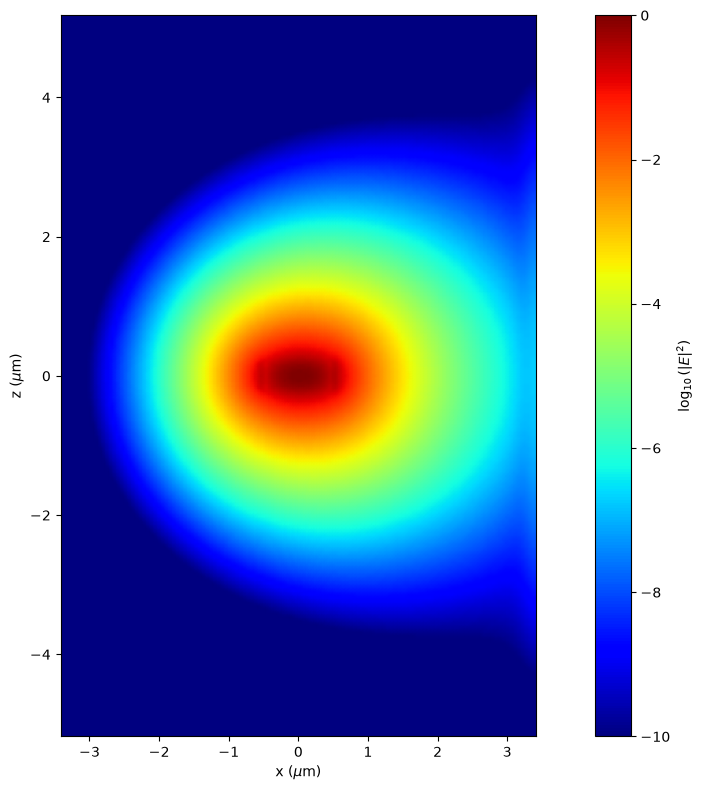

wavelength          1.550000e+00
n eff               1.642261e+00
k eff              -5.535776e-09
loss (dB/cm)       -1.949131e-03
TE (Ex) fraction    9.959077e-01
wg TE fraction      9.167890e-01
wg TM fraction      8.907690e-01
mode area           8.153263e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 30.0 µm ----------------
Solver radius: 30.0, Target neff: 1.642261
Field decay: -5.9933139501140325
---------------- Optimizing decay: -5.99 ----------------
New fde width: 6.099233124084837
Field decay: -6.442662949111813


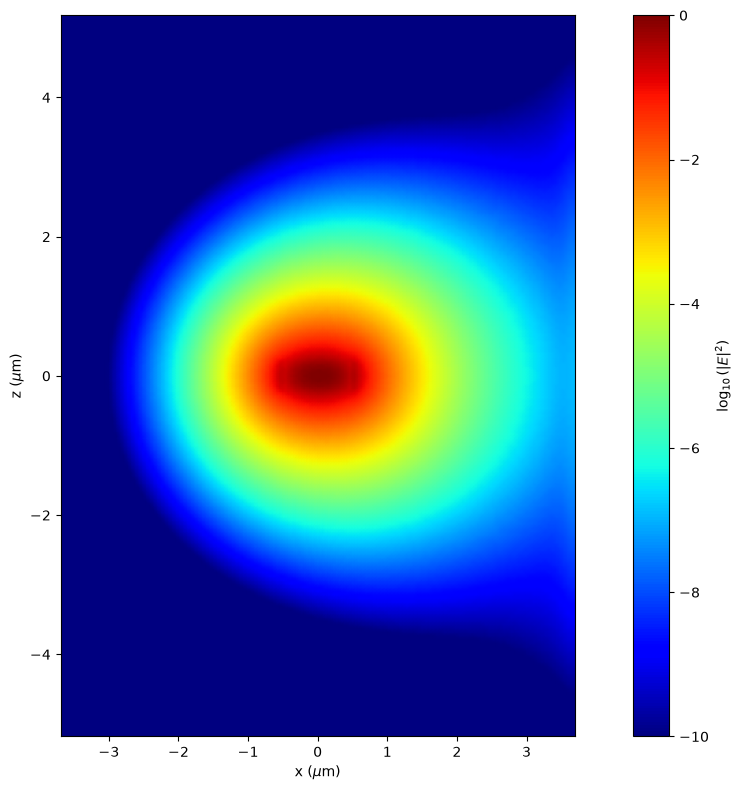

wavelength          1.550000e+00
n eff               1.644226e+00
k eff              -6.019452e-09
loss (dB/cm)       -2.119432e-03
TE (Ex) fraction    9.965014e-01
wg TE fraction      9.187854e-01
wg TM fraction      8.908456e-01
mode area           8.099011e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 29.5 µm ----------------
Solver radius: 29.5, Target neff: 1.644226
Field decay: -6.391105631723829


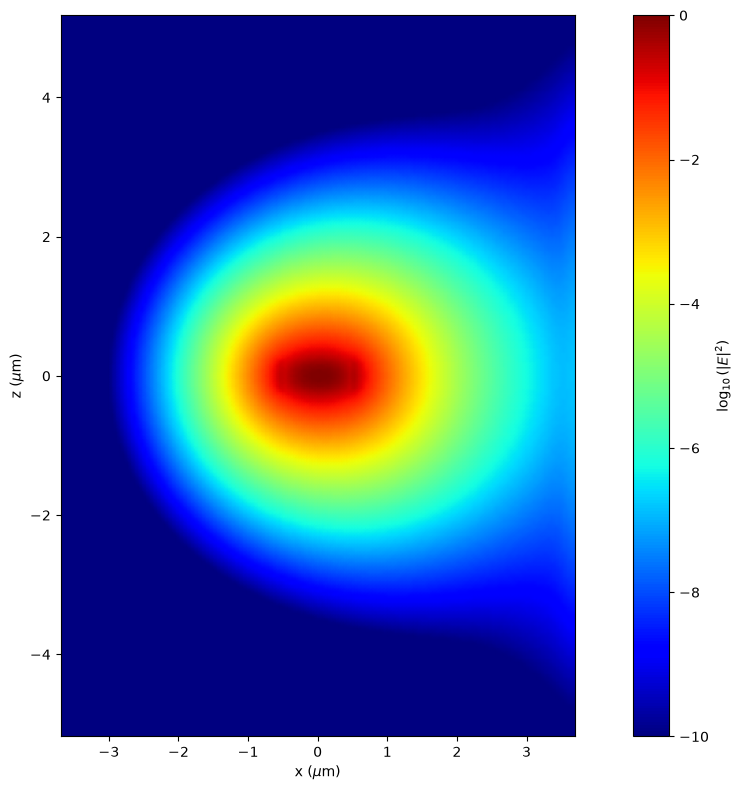

wavelength          1.550000e+00
n eff               1.644248e+00
k eff              -8.686510e-09
loss (dB/cm)       -3.058495e-03
TE (Ex) fraction    9.964972e-01
wg TE fraction      9.188089e-01
wg TM fraction      8.908564e-01
mode area           8.100992e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 29.0 µm ----------------
Solver radius: 29.0, Target neff: 1.644248
Field decay: -6.334390574848413


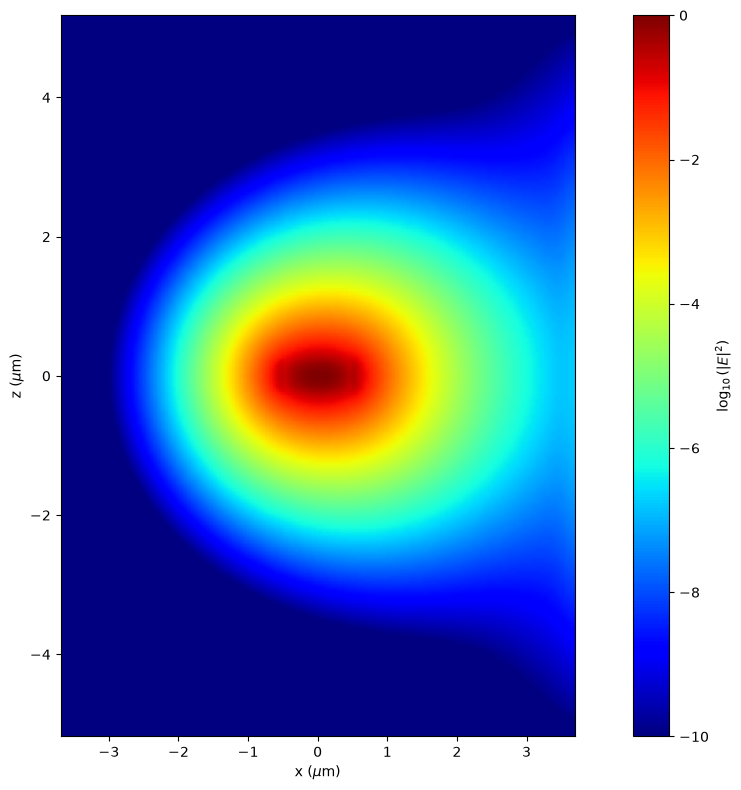

wavelength          1.550000e+00
n eff               1.644271e+00
k eff              -1.201578e-08
loss (dB/cm)       -4.230722e-03
TE (Ex) fraction    9.964927e-01
wg TE fraction      9.188336e-01
wg TM fraction      8.908678e-01
mode area           8.103089e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 28.5 µm ----------------
Solver radius: 28.5, Target neff: 1.644271
Field decay: -6.2713713959943


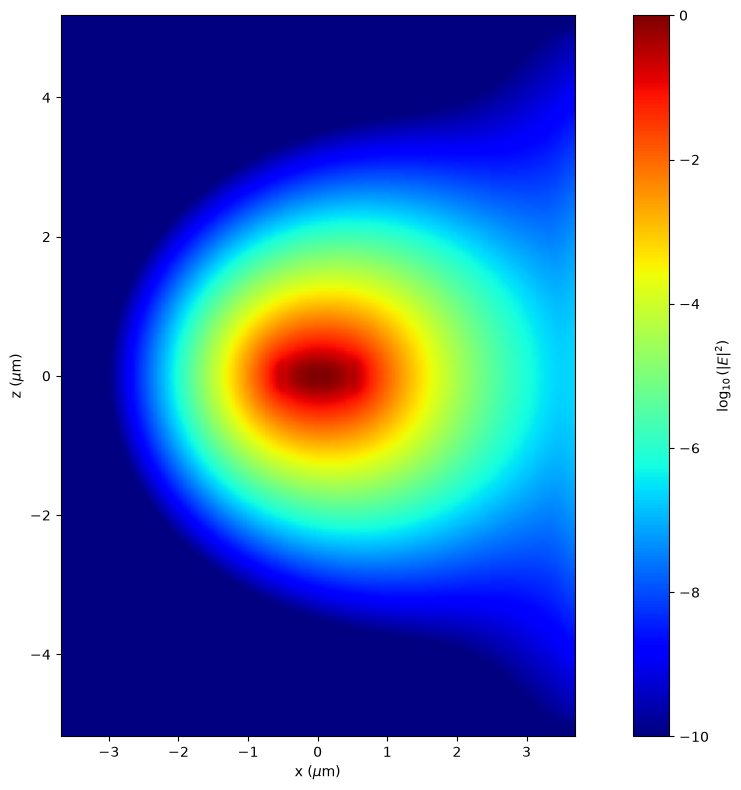

wavelength          1.550000e+00
n eff               1.644296e+00
k eff              -1.608299e-08
loss (dB/cm)       -5.662775e-03
TE (Ex) fraction    9.964880e-01
wg TE fraction      9.188598e-01
wg TM fraction      8.908798e-01
mode area           8.105310e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 28.0 µm ----------------
Solver radius: 28.0, Target neff: 1.644296
Field decay: -6.200692367647501


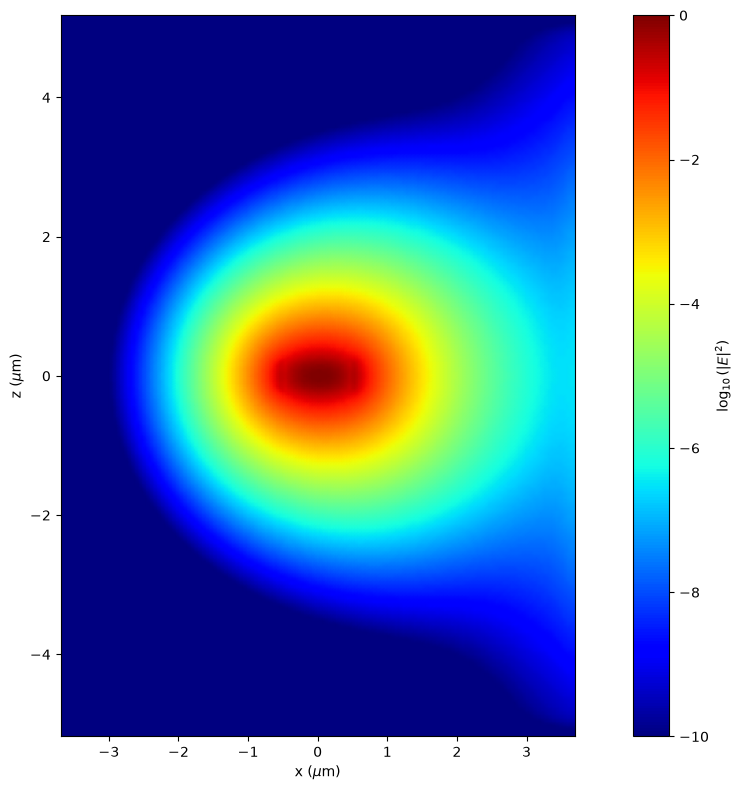

wavelength          1.550000e+00
n eff               1.644322e+00
k eff              -2.084965e-08
loss (dB/cm)       -7.341101e-03
TE (Ex) fraction    9.964830e-01
wg TE fraction      9.188877e-01
wg TM fraction      8.908926e-01
mode area           8.107669e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 27.5 µm ----------------
Solver radius: 27.5, Target neff: 1.644322
Field decay: -6.120900792102115


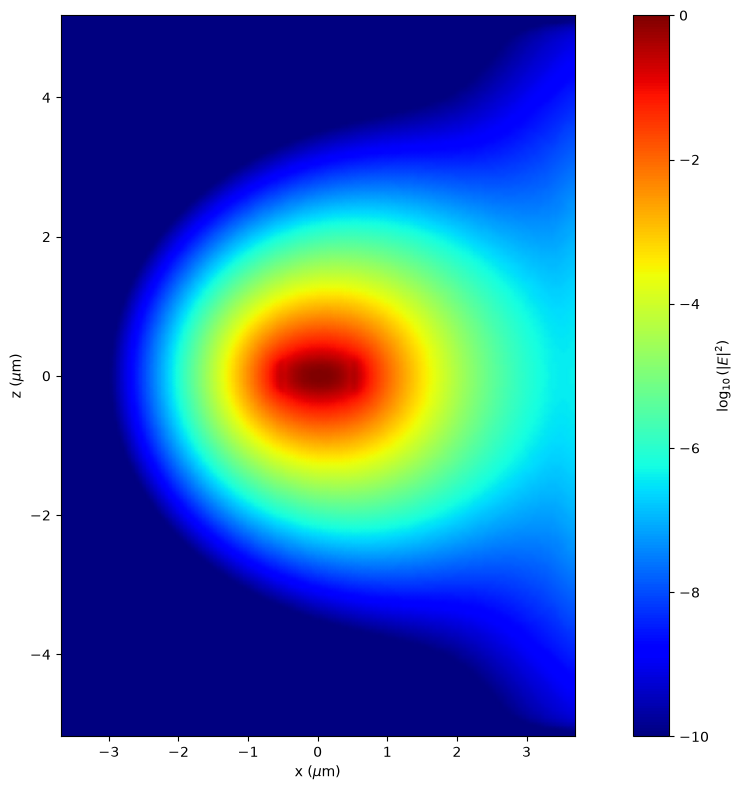

wavelength          1.550000e+00
n eff               1.644350e+00
k eff              -2.597766e-08
loss (dB/cm)       -9.146658e-03
TE (Ex) fraction    9.964778e-01
wg TE fraction      9.189172e-01
wg TM fraction      8.909062e-01
mode area           8.110178e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 27.0 µm ----------------
Solver radius: 27.0, Target neff: 1.644350
Field decay: -6.030768977426443


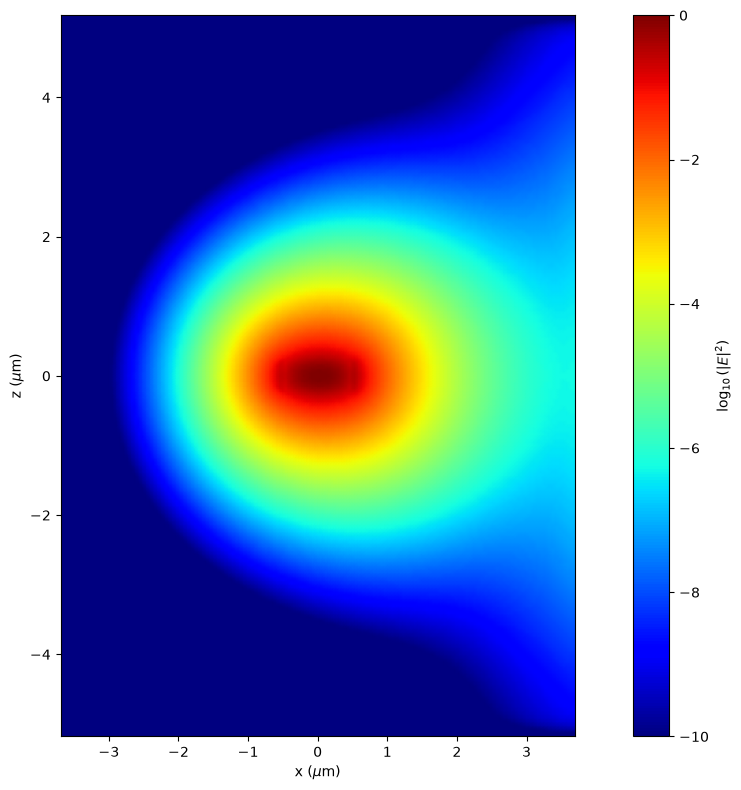

wavelength          1.550000e+00
n eff               1.644380e+00
k eff              -3.044270e-08
loss (dB/cm)       -1.071879e-02
TE (Ex) fraction    9.964723e-01
wg TE fraction      9.189487e-01
wg TM fraction      8.909206e-01
mode area           8.112854e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 26.5 µm ----------------
Solver radius: 26.5, Target neff: 1.644380
Field decay: -5.92997710275544
---------------- Optimizing decay: -5.93 ----------------
New fde width: 6.709156436493322
Field decay: -6.0196718933530935


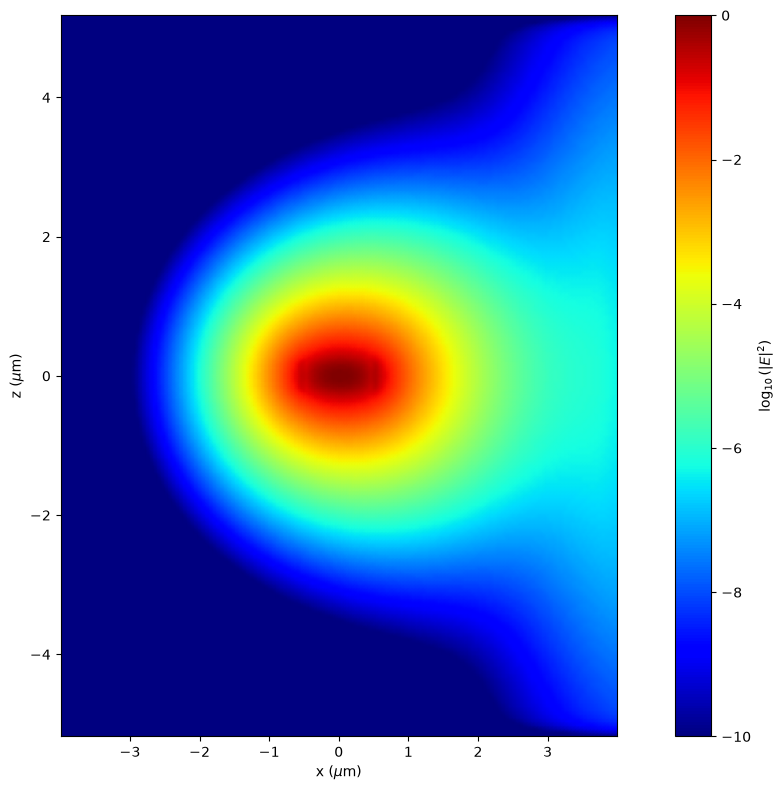

wavelength          1.550000e+00
n eff               1.644397e+00
k eff               4.968387e-08
loss (dB/cm)        1.749355e-02
TE (Ex) fraction    9.964662e-01
wg TE fraction      9.189809e-01
wg TM fraction      8.909443e-01
mode area           8.116001e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 26.0 µm ----------------
Solver radius: 26.0, Target neff: 1.644397
Field decay: -5.9408464185374426
---------------- Optimizing decay: -5.94 ----------------
New fde width: 7.3800720801426545
Field decay: -6.261359314011872


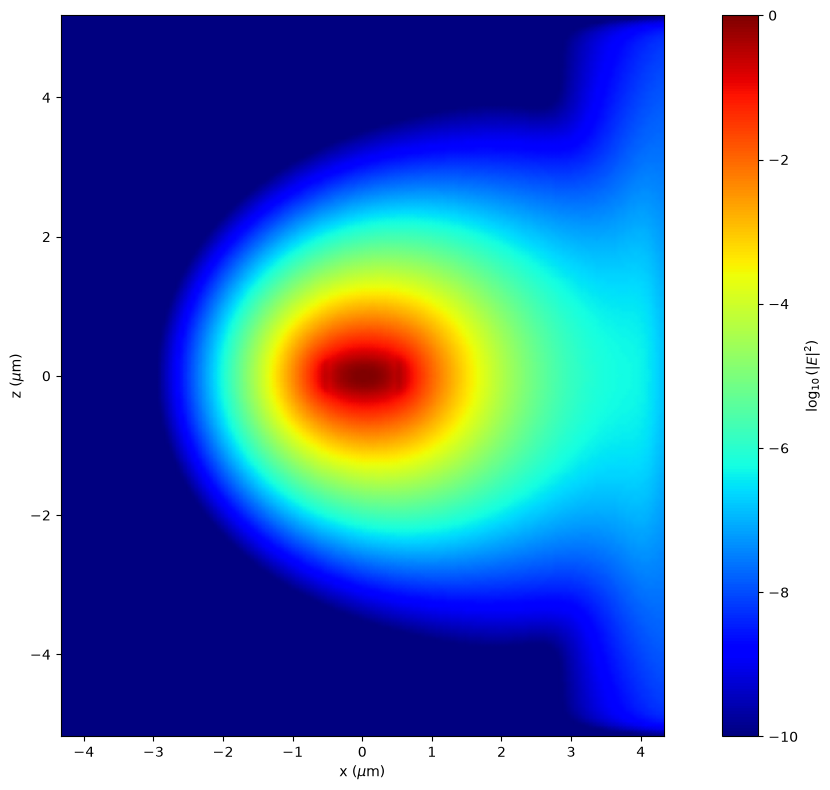

wavelength          1.550000e+00
n eff               1.644443e+00
k eff               8.478638e-08
loss (dB/cm)        2.985304e-02
TE (Ex) fraction    9.964609e-01
wg TE fraction      9.190180e-01
wg TM fraction      8.909554e-01
mode area           8.118655e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 25.5 µm ----------------
Solver radius: 25.5, Target neff: 1.644443
Field decay: -6.206341492607001


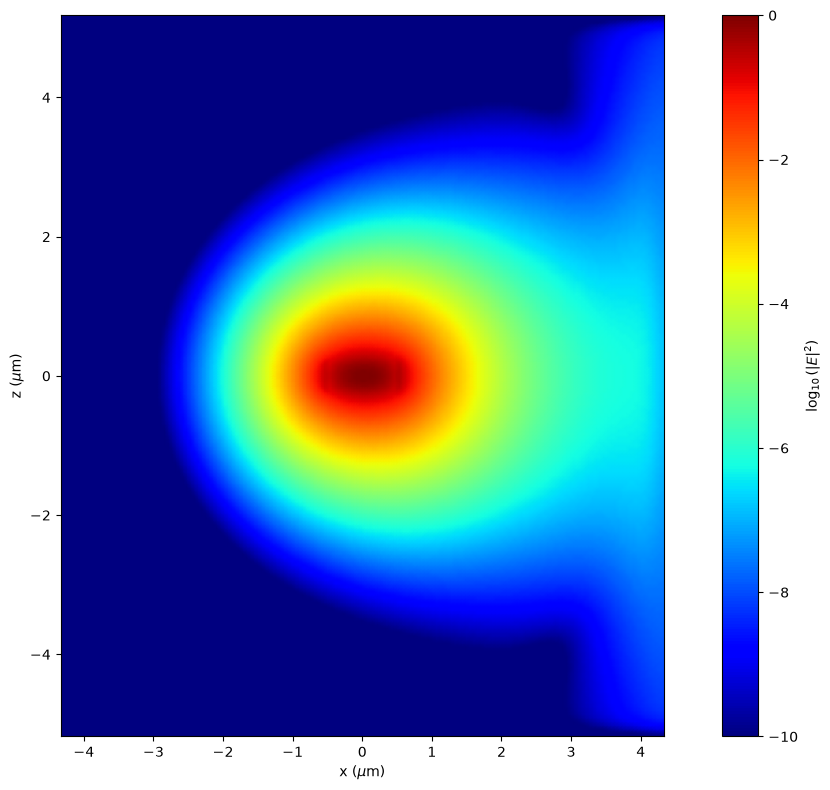

wavelength          1.550000e+00
n eff               1.644479e+00
k eff               1.031912e-07
loss (dB/cm)        3.633332e-02
TE (Ex) fraction    9.964543e-01
wg TE fraction      9.190557e-01
wg TM fraction      8.909727e-01
mode area           8.121874e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 25.0 µm ----------------
Solver radius: 25.0, Target neff: 1.644479
Field decay: -6.148315289226843


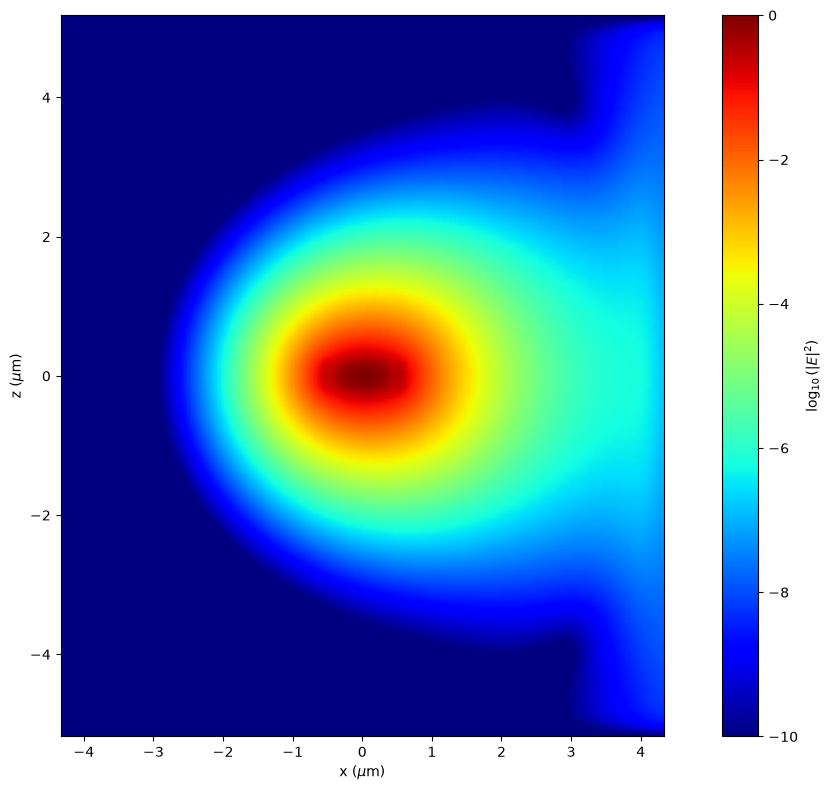

wavelength          1.550000e+00
n eff               1.644518e+00
k eff               1.253551e-07
loss (dB/cm)        4.413716e-02
TE (Ex) fraction    9.964473e-01
wg TE fraction      9.190960e-01
wg TM fraction      8.909912e-01
mode area           8.125321e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 24.5 µm ----------------
Solver radius: 24.5, Target neff: 1.644518
Field decay: -6.085892108267412


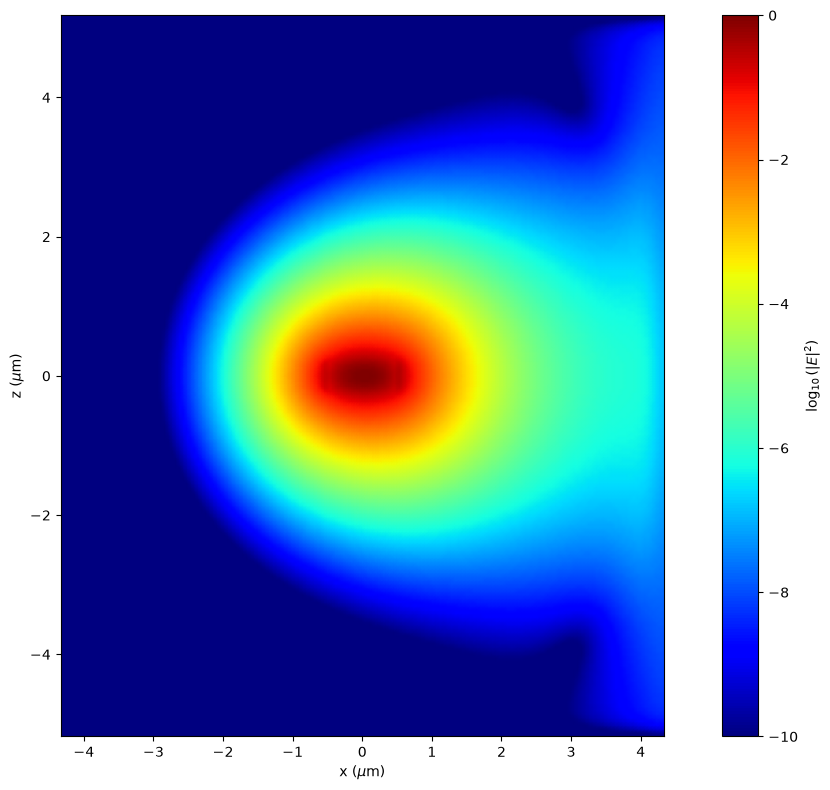

wavelength          1.550000e+00
n eff               1.644560e+00
k eff               1.527706e-07
loss (dB/cm)        5.379010e-02
TE (Ex) fraction    9.964398e-01
wg TE fraction      9.191392e-01
wg TM fraction      8.910110e-01
mode area           8.129020e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 24.0 µm ----------------
Solver radius: 24.0, Target neff: 1.644560
Field decay: -6.018328926024522


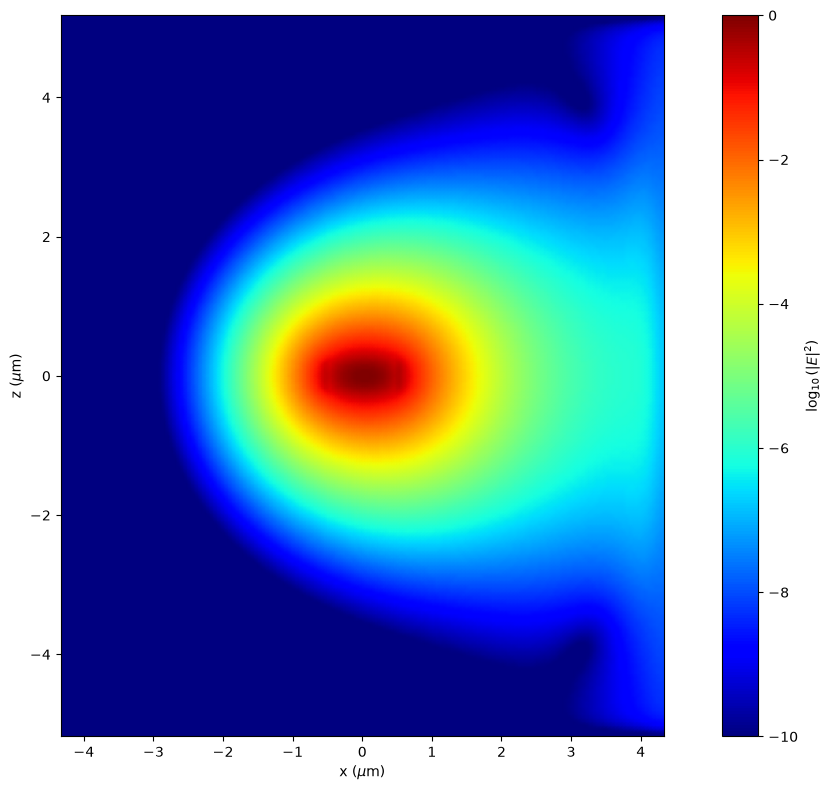

wavelength          1.550000e+00
n eff               1.644604e+00
k eff               1.874604e-07
loss (dB/cm)        6.600428e-02
TE (Ex) fraction    9.964319e-01
wg TE fraction      9.191855e-01
wg TM fraction      8.910322e-01
mode area           8.132998e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 23.5 µm ----------------
Solver radius: 23.5, Target neff: 1.644604
Field decay: -5.945416253511222
---------------- Optimizing decay: -5.95 ----------------
New fde width: 8.11807928815692
Field decay: -6.061178709448084


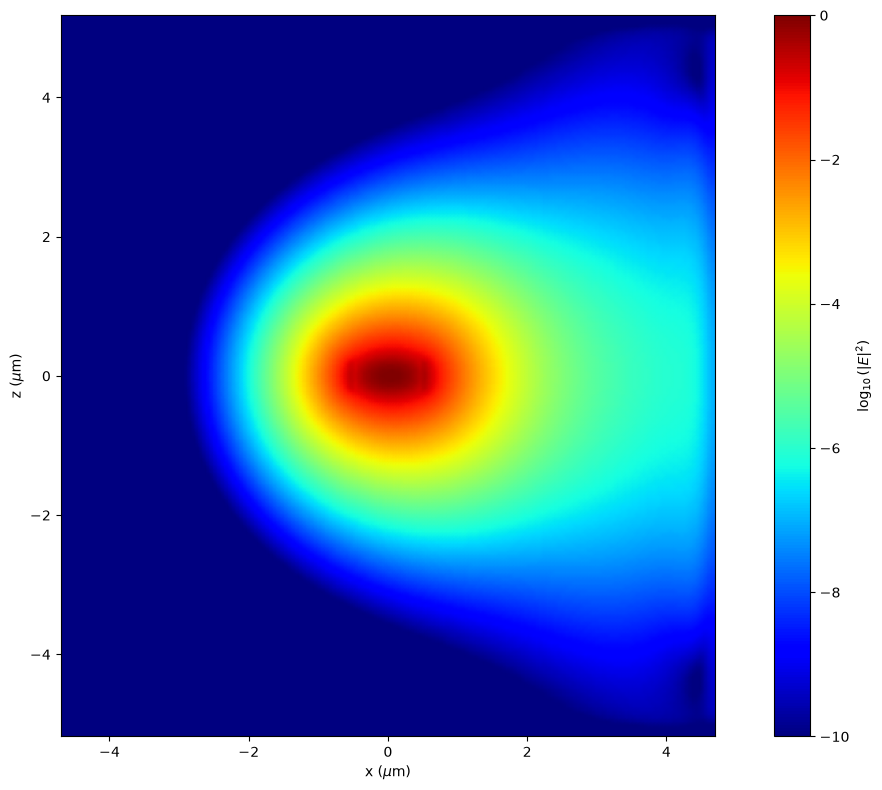

wavelength          1.550000e+00
n eff               1.642795e+00
k eff               2.333259e-07
loss (dB/cm)        8.215338e-02
TE (Ex) fraction    9.958634e-01
wg TE fraction      9.172843e-01
wg TM fraction      8.910063e-01
mode area           8.190894e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 23.0 µm ----------------
Solver radius: 23.0, Target neff: 1.642795
Field decay: -5.9574841531949
---------------- Optimizing decay: -5.96 ----------------
New fde width: 8.929887216972613
Field decay: -6.012858264430251


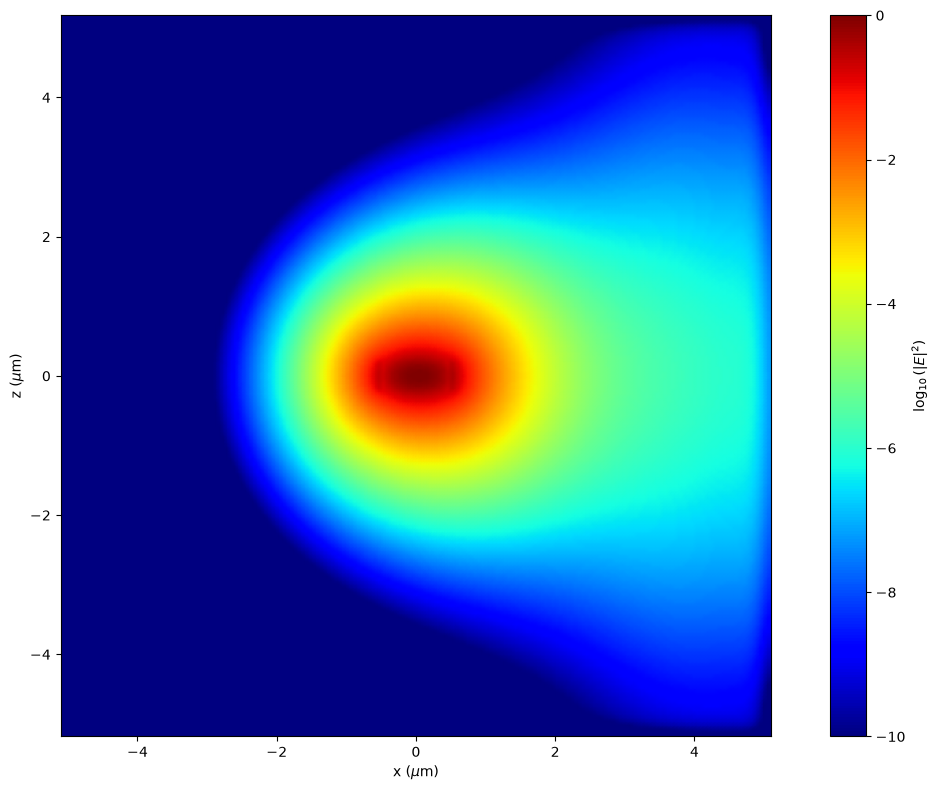

wavelength          1.550000e+00
n eff               1.642846e+00
k eff               3.439366e-07
loss (dB/cm)        1.210991e-01
TE (Ex) fraction    9.958559e-01
wg TE fraction      9.173412e-01
wg TM fraction      8.910342e-01
mode area           8.195984e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 22.5 µm ----------------
Solver radius: 22.5, Target neff: 1.642846
Field decay: -5.895455121993278
---------------- Optimizing decay: -5.90 ----------------
New fde width: 9.822875938669876
Field decay: -5.964774509923913
---------------- Optimizing decay: -5.96 ----------------
New fde width: 10.805163532536865
Field decay: -6.057640207356625


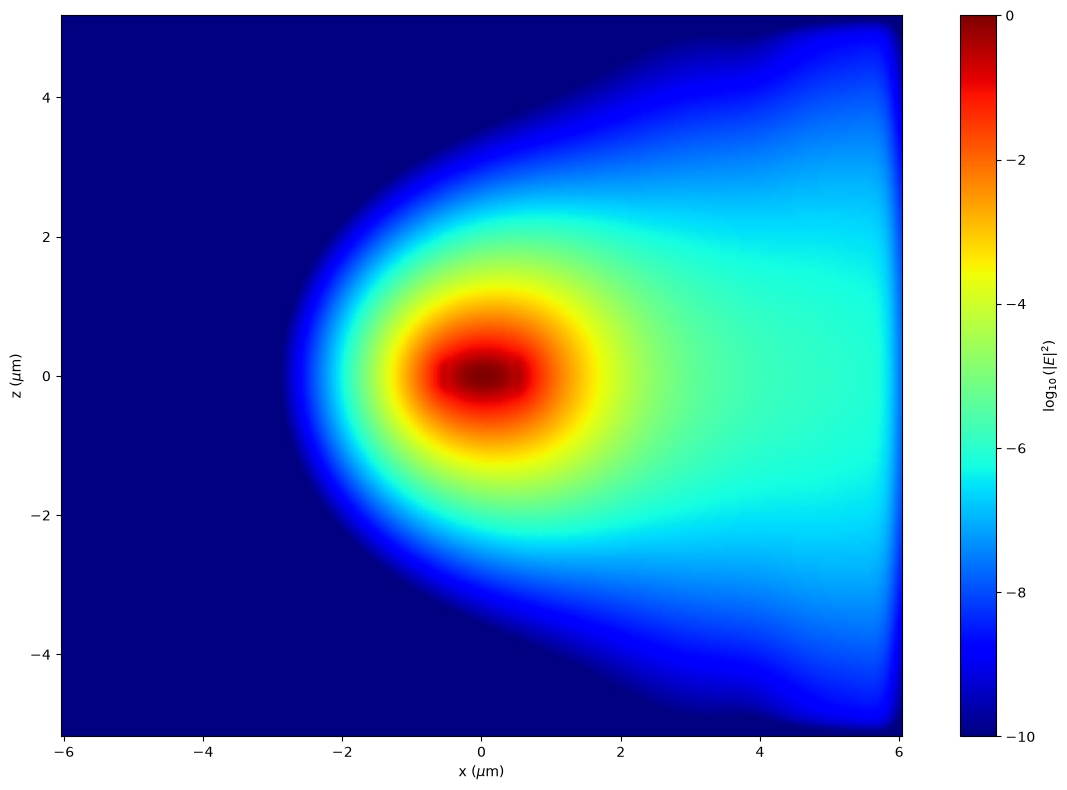

wavelength          1.550000e+00
n eff               1.642921e+00
k eff               4.468040e-07
loss (dB/cm)        1.573184e-01
TE (Ex) fraction    9.958516e-01
wg TE fraction      9.174019e-01
wg TM fraction      8.910609e-01
mode area           8.200451e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 22.0 µm ----------------
Solver radius: 22.0, Target neff: 1.642921
Field decay: -5.944769700516977
---------------- Optimizing decay: -5.94 ----------------
New fde width: 11.885679885790552
Field decay: -5.998158215521577
---------------- Optimizing decay: -6.00 ----------------
New fde width: 13.074247874369608
Field decay: -6.07319142348412


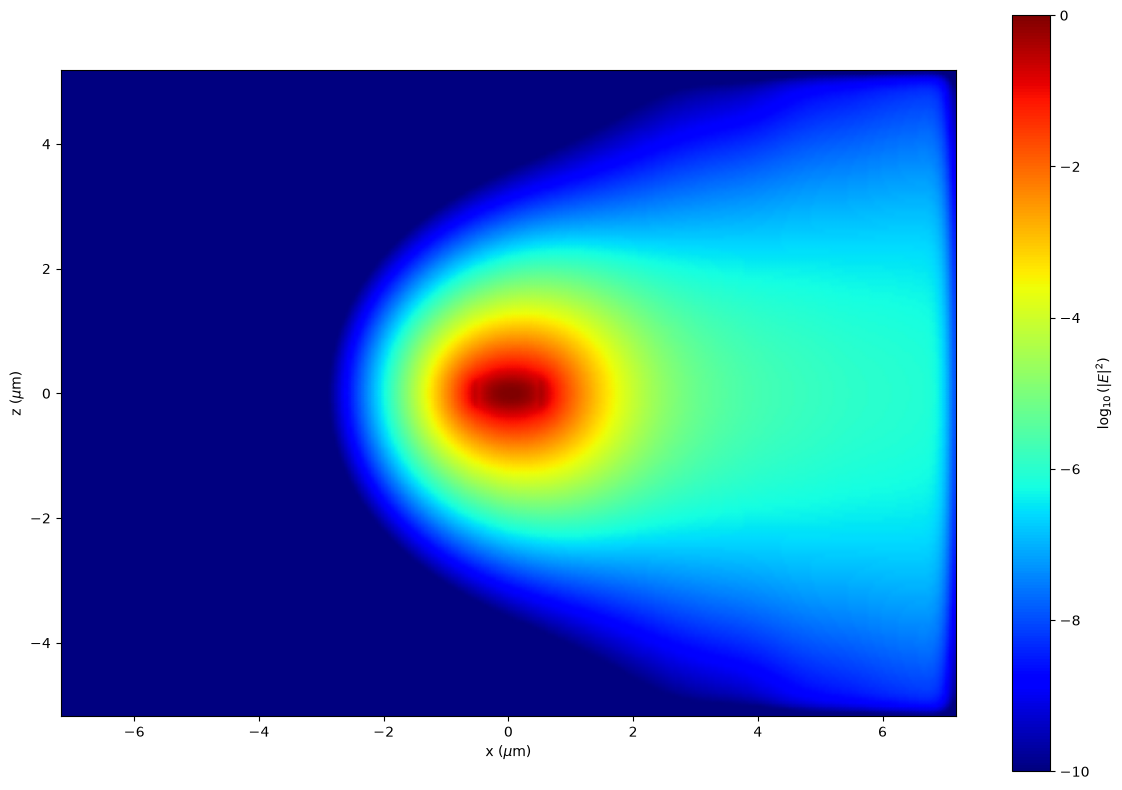

wavelength          1.550000e+00
n eff               1.643002e+00
k eff               6.012552e-07
loss (dB/cm)        2.117002e-01
TE (Ex) fraction    9.958422e-01
wg TE fraction      9.174645e-01
wg TM fraction      8.910803e-01
mode area           8.206092e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 21.5 µm ----------------
Solver radius: 21.5, Target neff: 1.643002
Field decay: -5.959222314704293
---------------- Optimizing decay: -5.96 ----------------
New fde width: 14.381672661806569
Field decay: -5.991334293939943
---------------- Optimizing decay: -5.99 ----------------
New fde width: 15.819839927987227
Field decay: -6.049911705462888


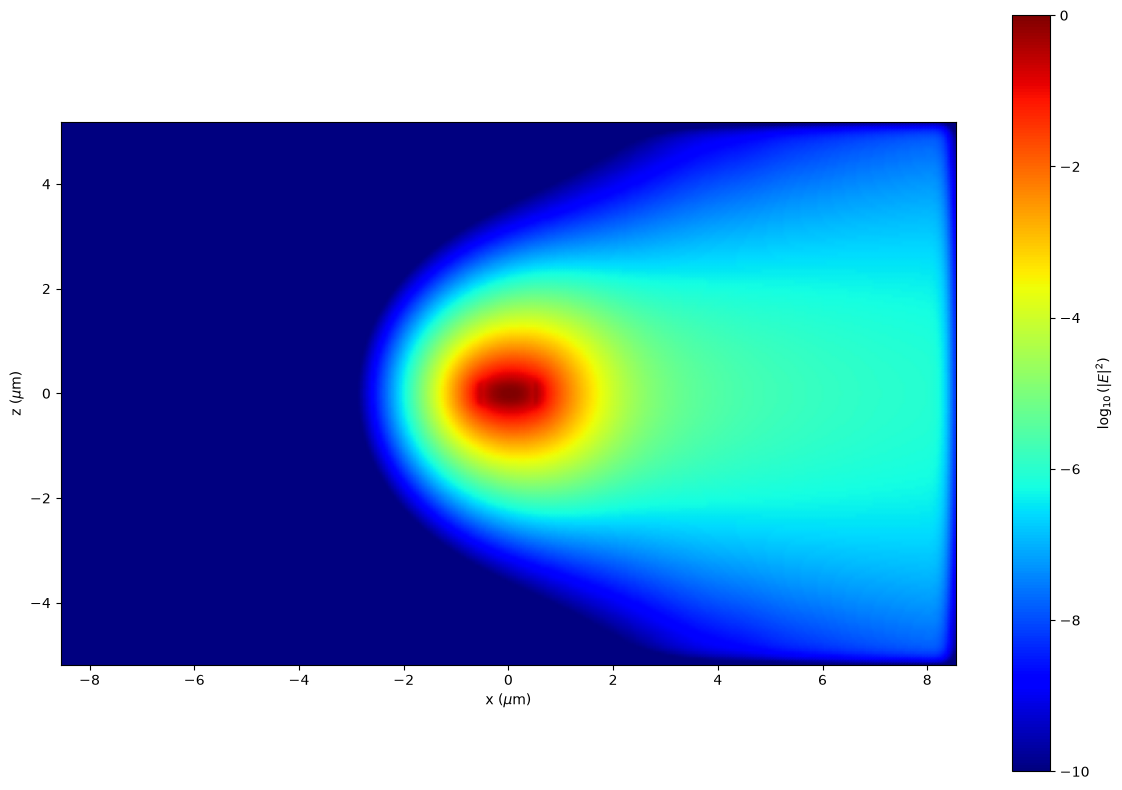

wavelength          1.550000e+00
n eff               1.642366e+00
k eff               8.643324e-07
loss (dB/cm)        3.043289e-01
TE (Ex) fraction    9.954026e-01
wg TE fraction      9.178028e-01
wg TM fraction      8.910312e-01
mode area           8.263226e-01
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 21.0 µm ----------------
Solver radius: 21.0, Target neff: 1.642366
Field decay: -5.93790937441238
---------------- Optimizing decay: -5.94 ----------------
New fde width: 17.40182392078595
Field decay: -6.025909067486126


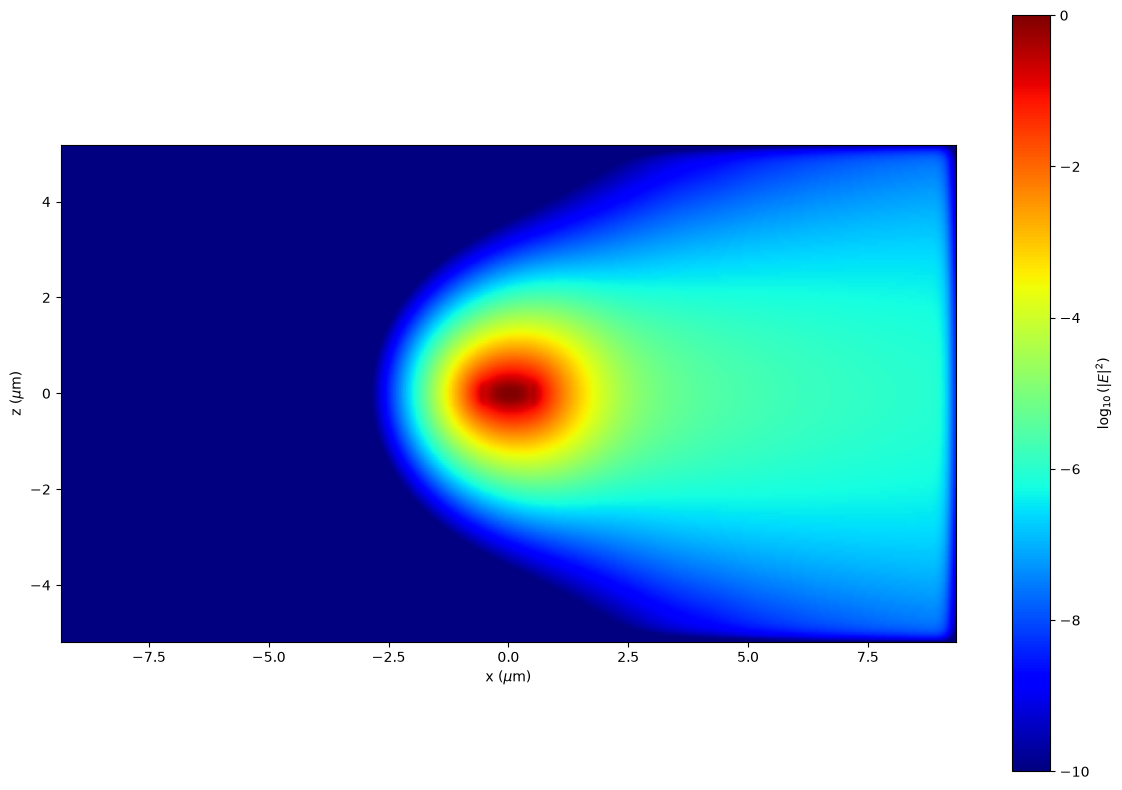

wavelength          1.550000
n eff               1.643138
k eff               0.000001
loss (dB/cm)        0.377043
TE (Ex) fraction    0.995830
wg TE fraction      0.917610
wg TM fraction      0.891170
mode area           0.821931
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 20.5 µm ----------------
Solver radius: 20.5, Target neff: 1.643138
Field decay: -5.9133384920317935
---------------- Optimizing decay: -5.91 ----------------
New fde width: 19.14200631286455
Field decay: -5.9721753918294365
---------------- Optimizing decay: -5.97 ----------------
New fde width: 21.056206944151004
Field decay: -6.030555642707376


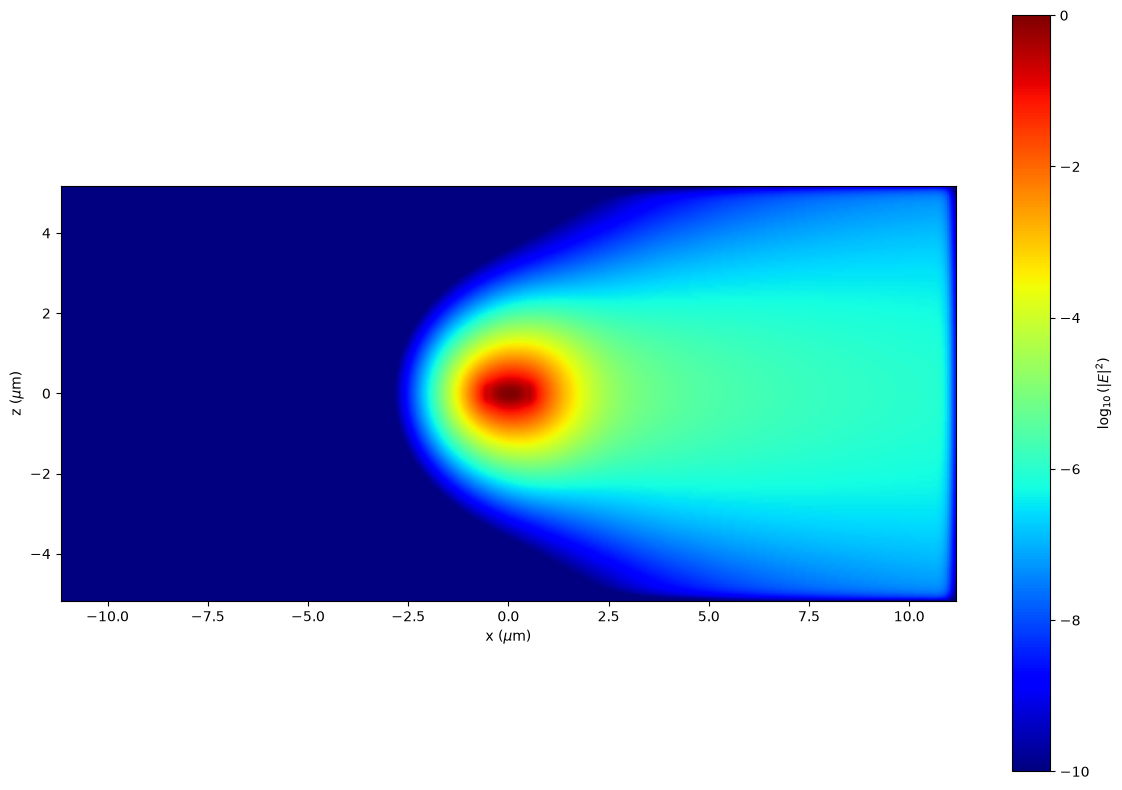

wavelength          1.550000
n eff               1.643225
k eff               0.000001
loss (dB/cm)        0.497482
TE (Ex) fraction    0.995822
wg TE fraction      0.917684
wg TM fraction      0.891214
mode area           0.822708
Name: (193414489032258.0625, 0), dtype: float64

---------------- Calculating for radius: 20.0 µm ----------------
Solver radius: 20.0, Target neff: 1.643225
Field decay: -5.91765683887458
---------------- Optimizing decay: -5.92 ----------------
New fde width: 23.161827638566105
Field decay: -5.945299083919731
---------------- Optimizing decay: -5.95 ----------------
New fde width: 25.47801040242272
Field decay: -6.0978575567042235


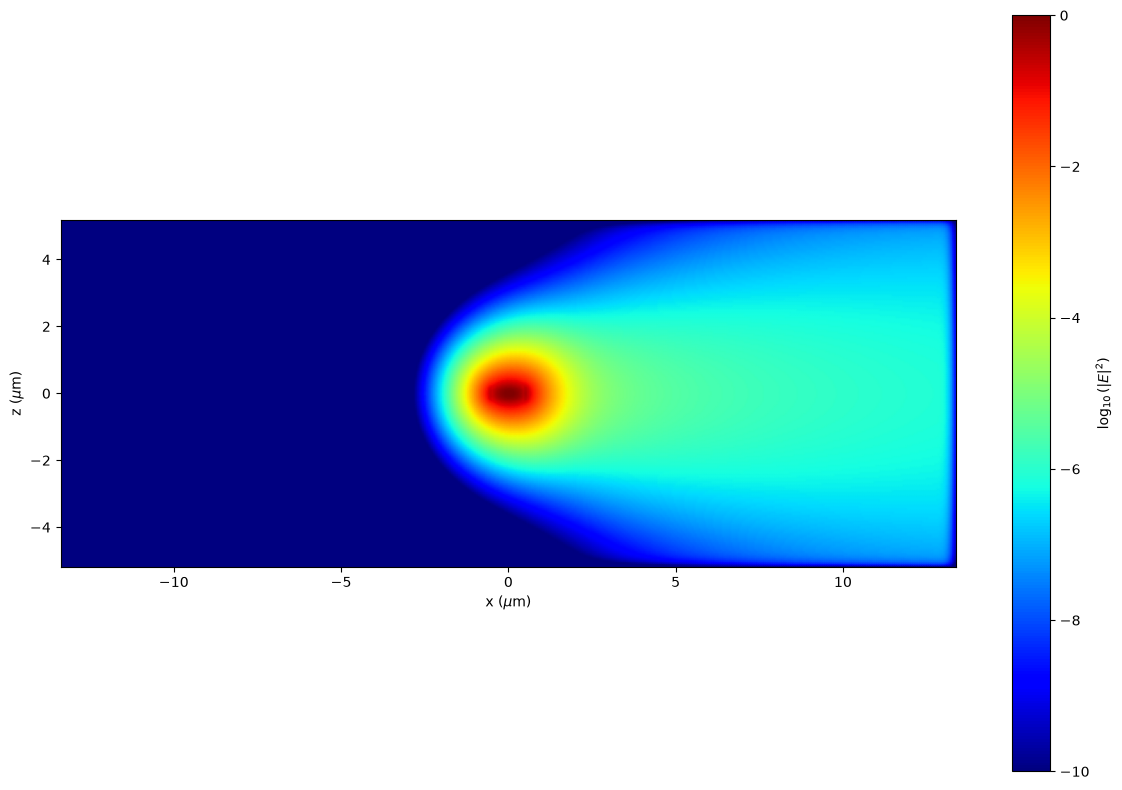

wavelength          1.550000
n eff               1.645110
k eff               0.000002
loss (dB/cm)        0.562456
TE (Ex) fraction    0.996346
wg TE fraction      0.919687
wg TM fraction      0.891296
mode area           0.818312
Name: (193414489032258.0625, 0), dtype: float64

In [15]:
def update_solver(old_mode_solver, radius_um, target_neff):
    print(f"Solver radius: {radius_um:.1f}, Target neff: {target_neff:.6f}")

    new_mode_solver = old_mode_solver.updated_copy(
        mode_spec = old_mode_solver.mode_spec.updated_copy(
            bend_radius=radius_um,
            target_neff=target_neff,
            bend_axis=1,
        )
    )

    return new_mode_solver

radius_data = {
    "radius": [],
    "neff": [],
    "f": [],
    "loss": [],
    "ng": [],
    "TE polarization fraction": [],
    "waveguide TE/TM fraction": [],
    "mode effective area": [],
    "Efield": [],
    "Hfield": [],
    "power coupling": []
}

decay = 0
# Start from biggest radii
radius_sweep = np.sort(radius_sweep)[::-1]
for r, radius in enumerate(radius_sweep):
    radius_um = radius*1e6
    print(f"---------------- Calculating for radius: {radius_um:.1f} µm ----------------")

    mode_solver = update_solver(mode_solver, radius_um, last_neff)
    mode_data = mode_solver.solve()
    
    Ex, Ey, Ez = (getattr(mode_data, c).isel(mode_index=0, f=0) for c in ["Ex", "Ey", "Ez"])
    decay = px.get_field_decay(Ex, Ey, Ez, margin=12)
    print(f"Field decay: {decay}")

    while decay > field_intensity_log_decay:
        print(f"---------------- Optimizing decay: {decay:.2f} ----------------")
        mode_solver = ensure_solver_decay(
            mode_data, 
            mode_solver, 
            field_intensity_log_decay
        )
        mode_data = mode_solver.solve()
    
        Ex, Ey, Ez = (getattr(mode_data, c).isel(mode_index=0, f=0) for c in ["Ex", "Ey", "Ez"])
        decay = px.get_field_decay(Ex, Ey, Ez, margin=12)
        print(f"Field decay: {decay}")

    x, z = mode_data.Ex.x, mode_data.Ex.z
    fig = px.plot_field(
        Ex, Ey, Ez, 
        x=x, z=z,
        vmin=-10, vmax=0,
    )
    plt.show()

    last_neff = mode_data.n_eff.sel(mode_index=0).item()
    mode_df = mode_data.to_dataframe().iloc[0]
    display(mode_df)

    # radius
    radius_data["radius"].append(radius)

    # neff
    neff = mode_df["n eff"]
    radius_data["neff"].append(neff)

    # # f
    # f = mode.getdata("FDE::data::mode1", "f")
    # radius_data["f"].append(f)

    # loss
    loss = mode_df["loss (dB/cm)"]
    radius_data["loss"].append(loss)

    # # ng
    # ng = mode.getdata("FDE::data::mode1", "ng").item()
    # radius_data["ng"].append(ng)

    # TE polarization fraction (%)
    te_fraction = mode_df["TE (Ex) fraction"]
    radius_data["TE polarization fraction"].append(te_fraction)

    # waveguide TE/TM fraction (%)
    # waveguide_fraction = mode.getdata("FDE::data::mode1", "waveguide TE/TM fraction")
    # radius_data["waveguide TE/TM fraction"].append(waveguide_fraction)

    # mode effective area (um^2)
    eff_area = mode_df["mode area"]
    radius_data["mode effective area"].append(eff_area)

    # Efield
    # Efield = mode.getresult("FDE::data::mode1", "E")
    # radius_data["Efield"].append(Efield)

    # Hfield
    # Hfield = mode.getresult("FDE::data::mode1", "H")
    # radius_data["Hfield"].append(Hfield)

    # Power coupling
    # power_coupling = mode.overlap("FDE::data::mode1", "straight_wg_mode1")[1]
    # radius_data["power coupling"].append(power_coupling)       

In [16]:
np.savez("radius_data.npz", **radius_data)

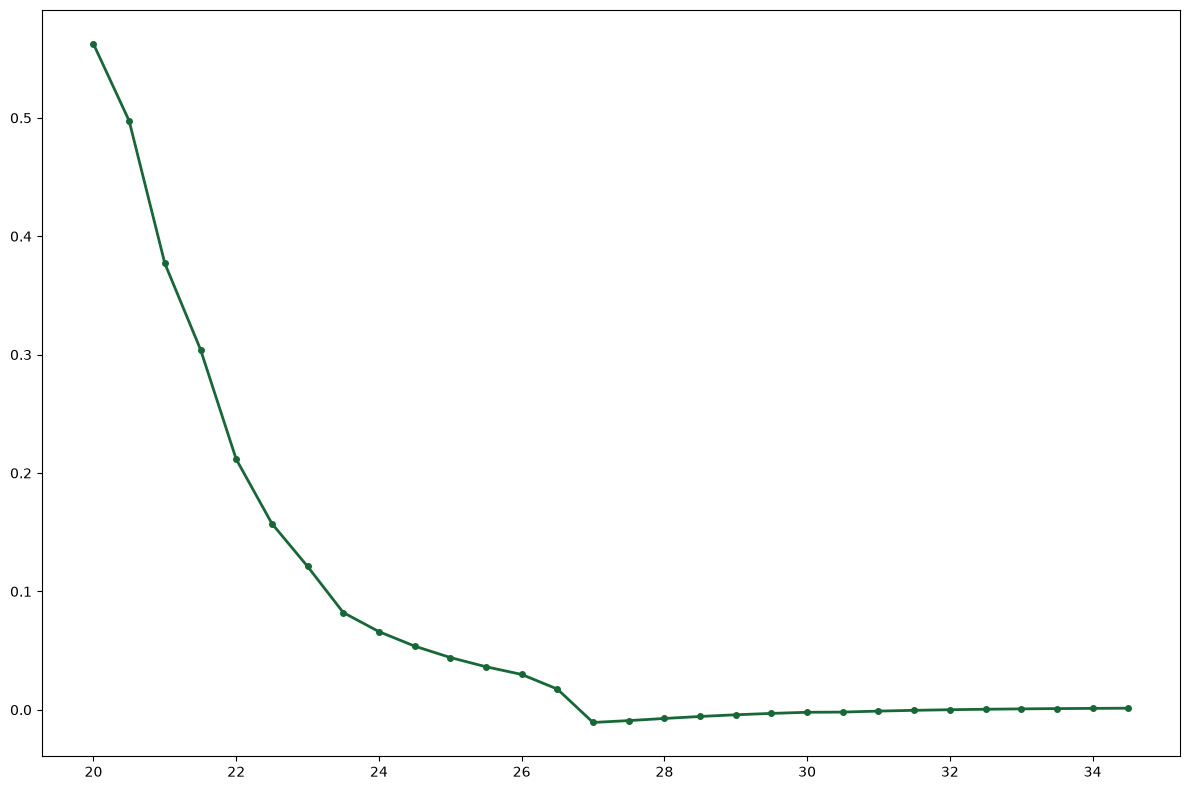

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

plt.plot(
    np.array(radius_data["radius"]) * 1e6,
    np.array(radius_data["loss"]),
    marker="o",
    markersize=4,
    linestyle="-",
    linewidth=2,
)


plt.tight_layout()
plt.show()